# 04c · Modelamiento de César: auditoría de errores y generalización

**Responsable:** César Rojas · **Etapas CRISP-DM:** Modeling y Evaluation.

**Pregunta:** ¿cómo se comportan los modelos de referencia, Ridge y árbol en la prueba común, y cómo cambian sus errores entre géneros, contenido explícito y artistas principales no vistos? El notebook también reproduce el análisis común de K-Means.

Se usa el [protocolo común](../docs/ea2/protocolo_comun.md) y el [plan EA2](../docs/ea2/plan_trabajo.md) para comparar resultados con los notebooks 04a y 04b. La fuente fue muestreada por género y no incluye fechas de extracción ni exposición promocional; estos resultados son retrospectivos y no prueban causalidad ni éxito futuro.

## 1. Fuente, preparación y controles

La EP1 halló 89.740 canciones únicas, 10,47% con popularidad cero y 3,48% con popularidad ≥ 70.
También encontró asociaciones acústicas individuales débiles, redundancia entre `energy` y
`loudness`, y una muestra artificialmente balanceada por género. Por eso se conserva una referencia
simple, se analizan errores por rangos y se evita extrapolar la prevalencia al catálogo completo.
Se regenera el procesado desde el CSV original con las reglas ya aprobadas, sin editar la fuente.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import sklearn
from IPython.display import display
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.dummy import DummyRegressor
from sklearn.linear_model import Ridge
from sklearn.metrics import adjusted_rand_score, silhouette_score
from sklearn.preprocessing import StandardScaler
from sklearn.tree import DecisionTreeRegressor

from spotify_popularity.analysis.exploratory import validate_processed_dataset
from spotify_popularity.config import PROJECT_PATHS
from spotify_popularity.data.loader import load_raw_dataset
from spotify_popularity.data.preparation import prepare_modeling_dataset
from spotify_popularity.data.provenance import sha256_file
from spotify_popularity.modeling.protocol import (
    CATEGORICAL_FEATURES,
    NUMERIC_FEATURES,
    SEED,
    model_pipeline,
    primary_artist,
    genre_only_pipeline,
    regression_metrics,
    split_primary_artist_ids,
    split_track_ids,
    top_decile_kpi,
)

source_hash = sha256_file(PROJECT_PATHS.raw_dataset)
data, preparation = prepare_modeling_dataset(load_raw_dataset())
controls = validate_processed_dataset(data)
assert controls["shape"] == (89_740, 20)
assert controls["missing_cells"] == 0
assert controls["duplicate_track_ids"] == 0
assert controls["non_positive_durations"] == 0
assert controls["empty_genres"] == 0
assert data["popularity"].between(0, 100).all()
print(f"Fuente SHA-256: {source_hash}")
print(f"scikit-learn/pandas: {sklearn.__version__} / {pd.__version__}")
print(f"Preparación: {preparation}")
display(pd.Series(controls, name="valor").to_frame())

Fuente SHA-256: b202fa49909b2d5cef71a04b1d21243cfeb36414535f2ca9272aa646721177bd
scikit-learn/pandas: 1.9.0 / 2.3.3
Preparación: PreparationSummary(input_rows=114000, invalid_rows_removed=1, output_rows=89740, repeated_track_ids_consolidated=24259)


,valor
shape,"(89740, 20)"
missing_cells,0
unique_track_ids,89740
duplicate_track_ids,0
non_positive_durations,0
empty_genres,0


## 2. Partición común y prevención de fuga

La unidad es `track_id`, ya deduplicada. Se ordenan los IDs antes de una separación 80/20 con
semilla 42; del entrenamiento se aparta 20% para validación. El conjunto de prueba queda reservado
hasta que se fijan parámetros y candidato recomendado. `track_id`, artistas, títulos y la variable
objetivo no entran en la matriz de predictores. La escala y los codificadores se ajustan dentro de
cada pipeline usando solo las filas disponibles para ese ajuste.

In [2]:
split = split_track_ids(data)
feature_columns = list(NUMERIC_FEATURES) + list(CATEGORICAL_FEATURES) + ["track_genres"]
indexed = data.set_index("track_id", drop=False)
fit_data = indexed.loc[list(split.fit_ids)]
validation_data = indexed.loc[list(split.validation_ids)]
train_data = indexed.loc[list(split.train_ids)]
test_data = indexed.loc[list(split.test_ids)]

X_fit, y_fit = fit_data[feature_columns], fit_data["popularity"]
X_validation, y_validation = validation_data[feature_columns], validation_data["popularity"]
X_train, y_train = train_data[feature_columns], train_data["popularity"]
X_test, y_test = test_data[feature_columns], test_data["popularity"]
assert not set(split.train_ids).intersection(split.test_ids)
assert set(split.fit_ids).union(split.validation_ids) == set(split.train_ids)
assert len(split.train_ids) == 71_792 and len(split.test_ids) == 17_948

print(f"Semilla: {SEED}")
print(
    f"Ajuste: {len(X_fit):,}; validación: {len(X_validation):,}; "
    f"entrenamiento total: {len(X_train):,}; prueba: {len(X_test):,}"
)
print(f"SHA-256 de IDs de prueba ordenados: {split.test_sha256}")
display(
    pd.DataFrame(
        {
            "partición": ["ajuste", "validación", "prueba"],
            "canciones": [len(X_fit), len(X_validation), len(X_test)],
            "popularidad_media": [y_fit.mean(), y_validation.mean(), y_test.mean()],
            "proporción_70_o_más": [
                y_fit.ge(70).mean(),
                y_validation.ge(70).mean(),
                y_test.ge(70).mean(),
            ],
        }
    ).round(3)
)

Semilla: 42


Ajuste: 57,433; validación: 14,359; entrenamiento total: 71,792; prueba: 17,948
SHA-256 de IDs de prueba ordenados: 7270ff57b6fb81215fba2f834942d194183e3854ccac935a65e5a03f7888b318


,partición,canciones,popularidad_media,proporción_70_o_más
0,ajuste,57433,33.138,0.035
1,validación,14359,33.174,0.033
2,prueba,17948,33.411,0.036


## 3. Algoritmos y selección con validación

`popularity` es numérica, por lo que se modela como regresión. La referencia predice la mediana
del entrenamiento y fija el error que debe superarse en MAE. Ridge regulariza una combinación
lineal y ayuda frente a predictores correlacionados; el árbol puede capturar umbrales e
interacciones, pero puede sobreajustar. Antes de consultar la prueba se comparan los `alpha` 0,1,
1, 10 y 100, y los árboles de profundidad 5, 10 o 15 con hojas mínimas de 20 o 100. Se elige por
MAE de validación, RMSE y menor complejidad para desempatar. Cada variante usa exactamente los
mismos IDs; la única diferencia del experimento personal es incluir `track_genres`.

In [3]:
ridge_grid = [{"alpha": alpha} for alpha in (0.1, 1.0, 10.0, 100.0)]
tree_grid = [
    {"max_depth": depth, "min_samples_leaf": leaf} for depth in (5, 10, 15) for leaf in (20, 100)
]


def estimator_for(model_name, parameters):
    if model_name == "Ridge":
        return Ridge(**parameters)
    return DecisionTreeRegressor(random_state=SEED, **parameters)


reference_validation = DummyRegressor(strategy="median").fit(X_fit, y_fit)
reference_validation_metrics = regression_metrics(
    y_validation, reference_validation.predict(X_validation)
)
validation_rows = []
for variant, include_genres in (("completo", True), ("sin_géneros", False)):
    for model_name, parameter_grid in (("Ridge", ridge_grid), ("Árbol", tree_grid)):
        for parameters in parameter_grid:
            estimator_name = "Ridge" if model_name == "Ridge" else "Árbol"
            pipeline = model_pipeline(
                estimator_for(estimator_name, parameters), include_genres=include_genres
            )
            pipeline.fit(X_fit, y_fit)
            scores = regression_metrics(y_validation, pipeline.predict(X_validation))
            complexity = (
                -parameters["alpha"]
                if model_name == "Ridge"
                else parameters["max_depth"] * 1000 - parameters["min_samples_leaf"]
            )
            validation_rows.append(
                {
                    "variante": variant,
                    "modelo": model_name,
                    "parámetros": parameters,
                    "complejidad": complexity,
                    **scores,
                }
            )

validation = pd.DataFrame(validation_rows)
selected = (
    validation.sort_values(["MAE", "RMSE", "complejidad"])
    .groupby(["variante", "modelo"], sort=False)
    .head(1)
    .sort_values(["variante", "MAE"])
    .reset_index(drop=True)
)
print("Referencia en validación:", reference_validation_metrics)
display(validation.sort_values(["variante", "modelo", "MAE"]).round(3))
print("Configuraciones seleccionadas usando solo validación:")
display(selected.round(3))

full_candidates = selected.loc[selected["variante"].eq("completo")].sort_values(
    ["MAE", "RMSE", "complejidad"]
)
recommended_before_test = (
    full_candidates.iloc[0]["modelo"]
    if full_candidates.iloc[0]["MAE"] < reference_validation_metrics["MAE"]
    else "Referencia"
)
print("Candidato recomendado antes de abrir la prueba:", recommended_before_test)

Referencia en validación: {'MAE': 17.207535343686885, 'RMSE': 20.535261977137537, 'R2': -7.188898482390904e-05}


,variante,modelo,parámetros,complejidad,MAE,RMSE,R2
0,completo,Ridge,{'alpha': 0.1},-0.1,11.786,16.430,0.360
1,completo,Ridge,{'alpha': 1.0},-1.0,11.788,16.430,0.360
2,completo,Ridge,{'alpha': 10.0},-10.0,11.818,16.435,0.359
3,completo,Ridge,{'alpha': 100.0},-100.0,12.169,16.574,0.349
8,completo,Árbol,"{'max_depth': 15, 'min_samples_leaf': 20}",14980.0,14.393,18.312,0.205
9,completo,Árbol,"{'max_depth': 15, 'min_samples_leaf': 100}",14900.0,14.442,18.360,0.201
6,completo,Árbol,"{'max_depth': 10, 'min_samples_leaf': 20}",9980.0,15.088,18.827,0.159
7,completo,Árbol,"{'max_depth': 10, 'min_samples_leaf': 100}",9900.0,15.109,18.852,0.157
4,completo,Árbol,"{'max_depth': 5, 'min_samples_leaf': 20}",4980.0,15.896,19.496,0.099
5,completo,Árbol,"{'max_depth': 5, 'min_samples_leaf': 100}",4900.0,15.898,19.496,0.099


Configuraciones seleccionadas usando solo validación:


,variante,modelo,parámetros,complejidad,MAE,RMSE,R2
0,completo,Ridge,{'alpha': 0.1},-0.1,11.786,16.430,0.360
1,completo,Árbol,"{'max_depth': 15, 'min_samples_leaf': 20}",14980.0,14.393,18.312,0.205
2,sin_géneros,Árbol,"{'max_depth': 15, 'min_samples_leaf': 20}",14980.0,15.627,19.830,0.067
3,sin_géneros,Ridge,{'alpha': 0.1},-0.1,16.581,20.162,0.036


Candidato recomendado antes de abrir la prueba: Ridge


## 4. Evaluación final en la prueba reservada

Se reajustan las cuatro configuraciones seleccionadas con las 71.792 canciones de entrenamiento.
La prueba se consulta una vez para las variantes declaradas de antemano. MAE y RMSE se expresan en
puntos de popularidad; RMSE penaliza más los errores grandes. R² compara el error cuadrático con
una constante igual a la media observada en la prueba; puede ser negativo. La diferencia de MAE
contra la referencia mediana muestra si el modelo aporta algo en esta muestra.

,variante,modelo,parámetros,MAE,RMSE,R2,mejora_MAE_puntos,mejora_MAE_pct
1,completo,Ridge,{'alpha': 0.1},11.915,16.643,0.348,5.335,30.929
2,completo,Árbol,"{'max_depth': 15, 'min_samples_leaf': 20}",14.508,18.460,0.198,2.742,15.898
0,referencia,Referencia,mediana,17.250,20.612,-0.000,0.000,0.000
3,sin_géneros,Árbol,"{'max_depth': 15, 'min_samples_leaf': 20}",15.693,19.834,0.074,1.557,9.026
4,sin_géneros,Ridge,{'alpha': 0.1},16.671,20.223,0.037,0.580,3.360


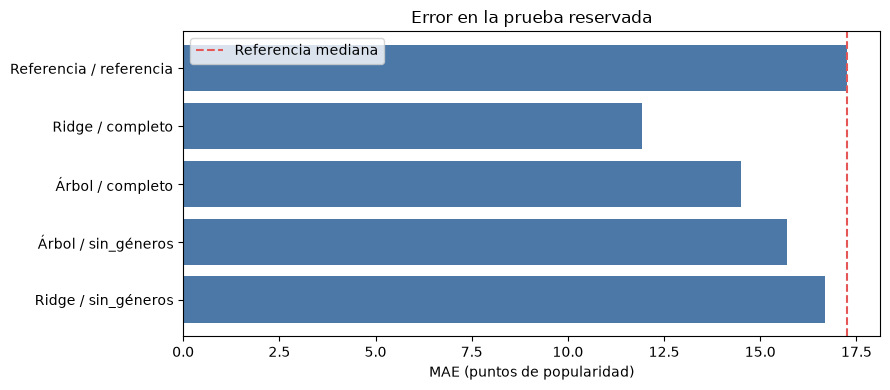

In [4]:
reference = DummyRegressor(strategy="median").fit(X_train, y_train)
predictions = {"Referencia": reference.predict(X_test)}
test_rows = [
    {
        "variante": "referencia",
        "modelo": "Referencia",
        "parámetros": "mediana",
        **regression_metrics(y_test, predictions["Referencia"]),
    }
]

for row in selected.itertuples(index=False):
    name = f"{row.modelo} / {row.variante}"
    pipeline = model_pipeline(
        estimator_for(row.modelo, row.parámetros),
        include_genres=row.variante == "completo",
    )
    pipeline.fit(X_train, y_train)
    predictions[name] = pipeline.predict(X_test)
    test_rows.append(
        {
            "variante": row.variante,
            "modelo": row.modelo,
            "parámetros": row.parámetros,
            **regression_metrics(y_test, predictions[name]),
        }
    )

test_scores = pd.DataFrame(test_rows)
baseline_mae = test_scores.loc[test_scores["modelo"].eq("Referencia"), "MAE"].iloc[0]
test_scores["mejora_MAE_puntos"] = baseline_mae - test_scores["MAE"]
test_scores["mejora_MAE_pct"] = 100 * test_scores["mejora_MAE_puntos"] / baseline_mae
display(test_scores.sort_values(["variante", "MAE"]).round(3))

plot_scores = test_scores.copy()
plot_scores["etiqueta"] = plot_scores["modelo"] + " / " + plot_scores["variante"]
fig, ax = plt.subplots(figsize=(9, 4))
ax.barh(plot_scores["etiqueta"], plot_scores["MAE"], color="#4C78A8")
ax.axvline(baseline_mae, color="#E45756", linestyle="--", label="Referencia mediana")
ax.set(xlabel="MAE (puntos de popularidad)", title="Error en la prueba reservada")
ax.invert_yaxis()
ax.legend()
plt.tight_layout()
figure_path = PROJECT_PATHS.figures / "ea2" / "04c_cesar_model_mae.png"
figure_path.parent.mkdir(parents=True, exist_ok=True)
fig.savefig(figure_path, dpi=150, bbox_inches="tight")
plt.show()

## 5. KPI retrospectivo y errores por segmentos

El umbral ≥ 70 proviene de EP1 y la capacidad de revisión se fija en el 10% antes de ver la prueba.
La precisión de esa lista se compara con la prevalencia en **esta muestra**; `lift > 1` significaría
un ranking mejor que una selección aleatoria de igual tamaño aquí, no utilidad comercial probada.
Se informa también qué proporción de todas las canciones ≥ 70 recupera la lista. Los rangos de
popularidad reales solo se usan para diagnosticar errores después de predecir.

In [5]:
kpi_rows = []
for name, predicted in predictions.items():
    kpi_rows.append({"modelo": name, **top_decile_kpi(test_data["track_id"], y_test, predicted)})
kpi = pd.DataFrame(kpi_rows).sort_values("lift", ascending=False)
display(kpi.round(3))

diagnostic_name = (
    "Referencia"
    if recommended_before_test == "Referencia"
    else f"{recommended_before_test} / completo"
)
errors = pd.DataFrame(
    {
        "actual": y_test.to_numpy(),
        "predicho": predictions[diagnostic_name],
        "explicit": test_data["explicit"].to_numpy(),
    }
)
errors["error_absoluto"] = (errors["actual"] - errors["predicho"]).abs()
errors["rango"] = np.select(
    [
        errors["actual"].eq(0),
        errors["actual"].between(0, 35, inclusive="neither"),
        errors["actual"].between(35, 70, inclusive="left"),
        errors["actual"].ge(70),
    ],
    ["0", "(0,35)", "[35,70)", "[70,100]"],
    default="fuera_de_rango",
)
print("Diagnóstico del candidato fijado en validación:", diagnostic_name)
display(
    errors.groupby("rango", sort=False)
    .agg(canciones=("actual", "size"), MAE=("error_absoluto", "mean"))
    .round(3)
)
display(
    errors.groupby("explicit", sort=False)
    .agg(canciones=("actual", "size"), MAE=("error_absoluto", "mean"))
    .round(3)
)

,modelo,seleccionadas,populares_en_seleccion,populares_en_prueba,prevalencia,precision,recall,lift
1,Ridge / completo,1795,159,653,0.036,0.089,0.243,2.435
4,Ridge / sin_géneros,1795,136,653,0.036,0.076,0.208,2.082
2,Árbol / completo,1795,119,653,0.036,0.066,0.182,1.822
3,Árbol / sin_géneros,1795,82,653,0.036,0.046,0.126,1.256
0,Referencia,1795,63,653,0.036,0.035,0.096,0.965


Diagnóstico del candidato fijado en validación: Ridge / completo


,canciones,MAE
rango,,
"(0,35)",7361,8.040
"[35,70)",8071,10.546
0,1863,24.448
"[70,100]",653,36.759


,canciones,MAE
explicit,,
False,16431,11.704
True,1517,14.198


### Predicción frente al valor real y errores extremos

Se visualizan todas las canciones de la prueba aleatoria con un mapa de densidad; la diagonal
representa predicción perfecta. Para explicar los errores grandes se mide el sesgo firmado
(`predicho − real`) en los rangos ya fijados, se cuentan los errores absolutos de al menos 40
puntos y se inspeccionan los diez mayores. Es un diagnóstico posterior a la selección del modelo:
no se ajustan parámetros ni se cambia el umbral del KPI usando estos casos.

Predicciones mínima/máxima: -31.636435844397063 79.7059969704323
Predicciones fuera de [0, 100]: 76 por debajo de 0 y 0 por encima de 100
Errores absolutos ≥ 40: 651 de 17948
Entre ellos, popularidad ≥ 70: 236 ; popularidad 0: 278
Canciones ≥ 70 predichas por debajo de 70: 653 de 653


,canciones,real_mediana,predicho_mediana,sesgo_medio,MAE,error_p90
rango,,,,,,
"(0,35)",7361,22.0,27.367,6.344,8.040,16.592
"[35,70)",8071,48.0,41.106,-8.607,10.546,23.808
0,1863,0.0,23.369,24.148,24.448,42.249
"[70,100]",653,74.0,40.035,-36.759,36.759,56.234


,track_id,track_name,artists,track_genres,actual,predicho,error_absoluto
11899,2grjqo0Frpf2okIBiifQKs,September,"Earth, Wind & Fire",disco|funk|jazz|soul,83.0,-11.18,94.18
2006,1IHWl5LamUGEuP4ozKQSXZ,Tití Me Preguntó,Bad Bunny,latin|latino|reggae|reggaeton,97.0,8.74,88.26
6356,3k3NWokhRRkEPhCzPmV8TW,Ojitos Lindos,Bad Bunny;Bomba Estéreo,latin|latino|reggae|reggaeton,94.5,8.92,85.58
7105,5Eax0qFko2dh7Rl2lYs3bx,Efecto,Bad Bunny,latin|latino|reggae|reggaeton,95.5,10.39,85.11
8827,6Rqn2GFlmvmV4w9Ala0I1e,Feeling Good,Nina Simone,blues|jazz|soul,73.0,-6.11,79.11
7883,1oew3nFNY3vMacJAsvry0S,Me And My Broken Heart,Rixton,dance|rock,79.0,5.39,73.61
12726,1IqF5PUDUnaykHLs0RWbDO,Time Moves Slow,BADBADNOTGOOD;Samuel T. Herring,jazz|soul,71.0,-2.03,73.03
16238,2QjOHCTQ1Jl3zawyYOpxh6,Sweater Weather,The Neighbourhood,alt-rock|alternative|pop|rock,93.0,20.16,72.84
15796,2gam98EZKrF9XuOkU13ApN,Promiscuous,Nelly Furtado;Timbaland,latin,82.0,9.71,72.29
11495,737gzPI5VAmgUGWiJ9yXuu,"1, 2, 3 (feat. Jason Derulo & De La Ghetto)",Sofía Reyes;Jason Derulo;De La Ghetto,dance|latin|pop,73.0,1.02,71.98


Ranking de 10%: populares recuperadas / omitidas: 159 / 494 ; canciones seleccionadas sin llegar a 70: 1636


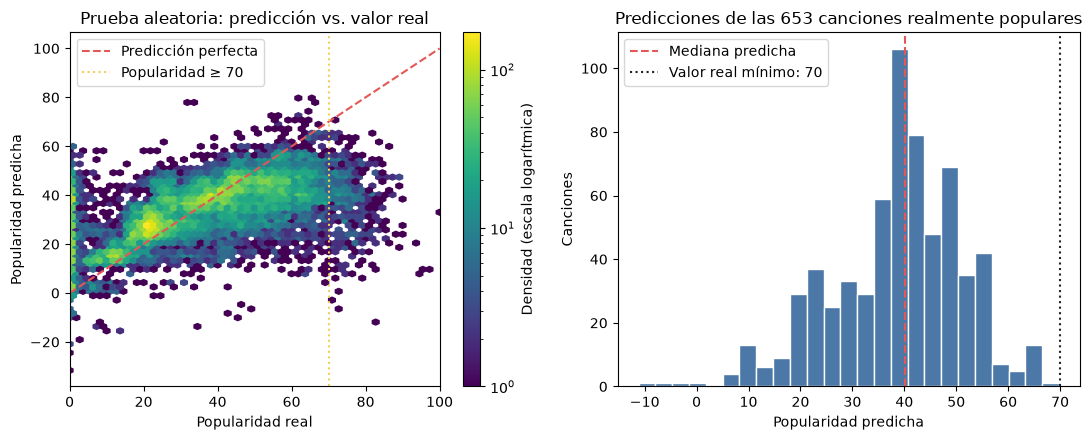

In [6]:
errors["track_id"] = test_data["track_id"].to_numpy()
errors["track_name"] = test_data["track_name"].to_numpy()
errors["artists"] = test_data["artists"].to_numpy()
errors["track_genres"] = test_data["track_genres"].to_numpy()
errors["sesgo"] = errors["predicho"] - errors["actual"]
high = errors.loc[errors["actual"].ge(70)]
extreme = errors.loc[errors["error_absoluto"].ge(40)]
print("Predicciones mínima/máxima:", errors["predicho"].min(), errors["predicho"].max())
print(
    "Predicciones fuera de [0, 100]:",
    errors["predicho"].lt(0).sum(),
    "por debajo de 0 y",
    errors["predicho"].gt(100).sum(),
    "por encima de 100",
)
print("Errores absolutos ≥ 40:", len(extreme), "de", len(errors))
print(
    "Entre ellos, popularidad ≥ 70:",
    extreme["actual"].ge(70).sum(),
    "; popularidad 0:",
    extreme["actual"].eq(0).sum(),
)
print("Canciones ≥ 70 predichas por debajo de 70:", high["predicho"].lt(70).sum(), "de", len(high))
display(
    errors.groupby("rango", sort=False)
    .agg(
        canciones=("actual", "size"),
        real_mediana=("actual", "median"),
        predicho_mediana=("predicho", "median"),
        sesgo_medio=("sesgo", "mean"),
        MAE=("error_absoluto", "mean"),
        error_p90=("error_absoluto", lambda values: values.quantile(0.90)),
    )
    .round(3)
)
display(
    errors.nlargest(10, "error_absoluto")[
        [
            "track_id",
            "track_name",
            "artists",
            "track_genres",
            "actual",
            "predicho",
            "error_absoluto",
        ]
    ].round(2)
)

ranked_errors = errors.sort_values(["predicho", "track_id"], ascending=[False, True])
top_capacity = int(np.ceil(len(errors) * 0.10))
top_errors = ranked_errors.iloc[:top_capacity]
popular_captured = int(top_errors["actual"].ge(70).sum())
print(
    "Ranking de 10%: populares recuperadas / omitidas:",
    popular_captured,
    "/",
    len(high) - popular_captured,
    "; canciones seleccionadas sin llegar a 70:",
    top_capacity - popular_captured,
)

fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
density = axes[0].hexbin(
    errors["actual"],
    errors["predicho"],
    gridsize=55,
    mincnt=1,
    bins="log",
    cmap="viridis",
)
axes[0].plot([0, 100], [0, 100], color="#E45756", linestyle="--", label="Predicción perfecta")
axes[0].axvline(70, color="#F2CF5B", linestyle=":", label="Popularidad ≥ 70")
axes[0].set(
    xlim=(0, 100),
    xlabel="Popularidad real",
    ylabel="Popularidad predicha",
    title="Prueba aleatoria: predicción vs. valor real",
)
axes[0].legend(loc="upper left")
fig.colorbar(density, ax=axes[0], label="Densidad (escala logarítmica)")
axes[1].hist(high["predicho"], bins=25, color="#4C78A8", edgecolor="white")
axes[1].axvline(
    high["predicho"].median(), color="#E45756", linestyle="--", label="Mediana predicha"
)
axes[1].axvline(70, color="#222222", linestyle=":", label="Valor real mínimo: 70")
axes[1].set(
    xlabel="Popularidad predicha",
    ylabel="Canciones",
    title=f"Predicciones de las {len(high)} canciones realmente populares",
)
axes[1].legend()
plt.tight_layout()
figure_path = PROJECT_PATHS.figures / "ea2" / "04c_cesar_predictions_vs_actual.png"
fig.savefig(figure_path, dpi=150, bbox_inches="tight")
plt.show()

### Lectura del ranking retrospectivo

La tabla anterior compara referencia, Ridge y árbol con y sin géneros bajo la misma prueba. Interpreta precisión, exhaustividad y *lift* frente a la prevalencia de esta muestra. La lista es una simulación retrospectiva: las canciones seleccionadas no representan una decisión de promoción y el valor real de popularidad ya existe en los datos.

## 6. Aporte individual: auditoría por contenido explícito y género

Se auditan los errores del candidato fijado usando los mismos resultados de la prueba. Para `explicit` se informa el número de canciones, MAE, RMSE y recuperación de canciones con popularidad ≥ 70. Para género se expande `track_genres` después de predecir; una canción multietiqueta aparece una vez en cada género que tiene asignado. El soporte se cuenta por `track_id` único dentro de cada género y se muestra solo desde 100 canciones para evitar interpretar grupos muy pequeños. Estas comparaciones describen diferencias de error, no efectos causales.

Errores por contenido explícito; diagnóstico del candidato fijado en validación:


,explicit,canciones,MAE,RMSE,sesgo_medio,populares_ge_70,recuperadas_ge_70,recall_ge_70
0,False,16431,11.704,16.392,-0.120,543,0,0.0
1,True,1517,14.198,19.153,0.117,110,0,0.0


Errores por género (soporte mínimo: 100 canciones únicas):


,genero,canciones,MAE,RMSE,sesgo_medio,populares_ge_70,recuperadas_ge_70,recall_ge_70
0,ska,232,5.035,9.286,-1.152,2,0,0.0
1,study,231,11.637,13.591,-0.722,0,0,NaN
2,sleep,226,14.581,19.883,-0.375,1,0,0.0
3,kids,225,7.075,10.851,-0.542,0,0,NaN
4,mandopop,224,10.889,13.777,0.076,1,0,0.0
...,...,...,...,...,...,...,...,...
109,malay,171,8.902,11.296,0.793,0,0,NaN
110,techno,170,13.683,17.837,-0.470,3,0,0.0
111,jazz,169,18.809,23.219,1.296,5,0,0.0
112,classical,169,14.207,17.622,-1.545,1,0,0.0


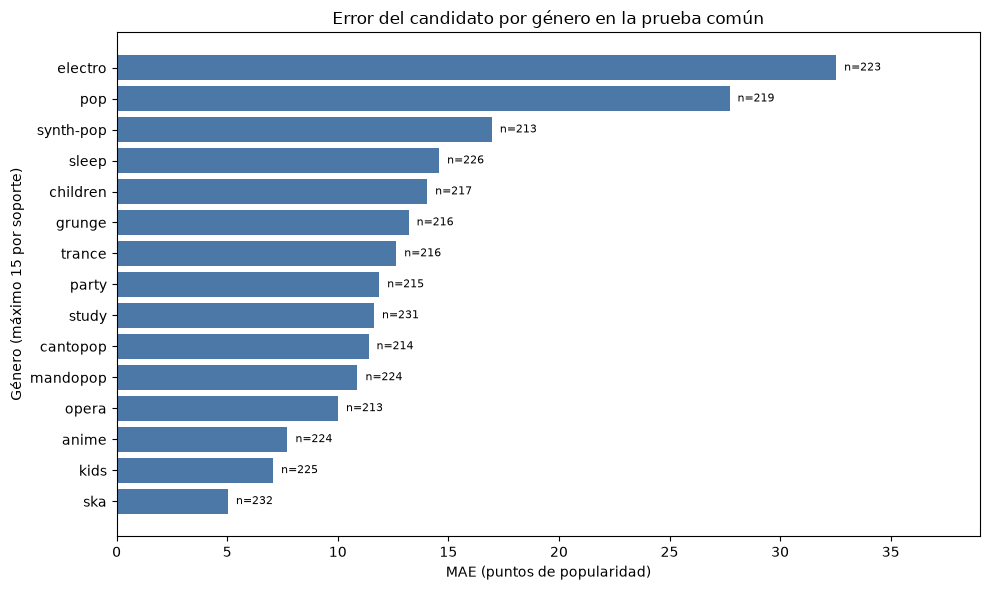

Figura guardada en: reports\figures\ea2\04c_cesar_segment_errors.png


In [7]:
segment_frame = pd.DataFrame(
    {
        "track_id": test_data["track_id"].to_numpy(),
        "actual": y_test.to_numpy(),
        "predicho": predictions[diagnostic_name],
        "explicit": test_data["explicit"].to_numpy(),
        "track_genres": test_data["track_genres"].to_numpy(),
    }
)
segment_frame["error_absoluto"] = (segment_frame["actual"] - segment_frame["predicho"]).abs()
segment_frame["error_firmado"] = segment_frame["predicho"] - segment_frame["actual"]


def segment_metrics(frame, label_column):
    rows = []
    for label, group in frame.groupby(label_column, dropna=False, sort=True):
        popular = group["actual"].ge(70)
        retrieved = popular & group["predicho"].ge(70)
        rows.append(
            {
                label_column: label,
                "canciones": group["track_id"].nunique(),
                "MAE": group["error_absoluto"].mean(),
                "RMSE": np.sqrt(np.mean(np.square(group["actual"] - group["predicho"]))),
                "sesgo_medio": group["error_firmado"].mean(),
                "populares_ge_70": int(popular.sum()),
                "recuperadas_ge_70": int(retrieved.sum()),
                "recall_ge_70": retrieved.sum() / popular.sum() if popular.sum() else np.nan,
            }
        )
    return pd.DataFrame(rows)

explicit_summary = segment_metrics(segment_frame, "explicit")
print("Errores por contenido explícito; diagnóstico del candidato fijado en validación:")
display(explicit_summary.round(3))

genres_long = segment_frame.assign(
    genero=segment_frame["track_genres"].str.split("|", regex=False)
).explode("genero")
genre_summary = segment_metrics(genres_long, "genero")
genre_summary = genre_summary.loc[genre_summary["canciones"].ge(100)].sort_values(
    ["canciones", "MAE"], ascending=[False, False]
).reset_index(drop=True)
print("Errores por género (soporte mínimo: 100 canciones únicas):")
display(genre_summary.round(3))

plot_genres = genre_summary.head(15).sort_values("MAE")
fig, ax = plt.subplots(figsize=(10, 6))
ax.barh(plot_genres["genero"], plot_genres["MAE"], color="#4C78A8")
ax.set(
    xlabel="MAE (puntos de popularidad)",
    ylabel="Género (máximo 15 por soporte)",
    title="Error del candidato por género en la prueba común",
)
ax.set_xlim(0, plot_genres["MAE"].max() * 1.2)
for y_position, (_, row) in enumerate(plot_genres.iterrows()):
    ax.text(row["MAE"], y_position, f"  n={int(row['canciones']):,}", va="center", fontsize=8)
plt.tight_layout()
figure_path = PROJECT_PATHS.figures / "ea2" / "04c_cesar_segment_errors.png"
figure_path.parent.mkdir(parents=True, exist_ok=True)
fig.savefig(figure_path, dpi=150, bbox_inches="tight")
plt.show()
print("Figura guardada en:", figure_path.relative_to(PROJECT_PATHS.root))


### Cómo leer las diferencias por segmento

Un MAE mayor en un segmento señala dónde el candidato se equivoca más en esta prueba; no explica por qué ocurre. En el desglose por género, las canciones con varias etiquetas contribuyen a varios grupos, así que los soportes no se deben sumar para reconstruir el total de canciones. Compara tamaños y tasas de recuperación antes de interpretar brechas. Las categorías poco frecuentes pueden tener estimaciones inestables.

En esta ejecución, ninguna canción con popularidad real ≥ 70 recibió una predicción ≥ 70. Por eso el `recall_ge_70` basado en umbral es cero en los segmentos, mientras que la métrica de ranking del 10% recupera algunas canciones al ordenar predicciones relativamente altas. Son dos lecturas distintas del mismo regresor.

## 7. Diagnóstico de generalización por artista principal

El grupo es el primer nombre de `artists` antes de `;`, normalizado sin espacios laterales y sin
distinguir mayúsculas. Se crean prueba y validación con `GroupShuffleSplit` independiente de la
partición aleatoria; el 20% se aplica a grupos, por lo que las cantidades de canciones pueden
diferir. Ningún artista **principal** debe aparecer en dos particiones. Las colaboraciones con
artistas secundarios se cuentan aparte. Se repiten los mismos candidatos para `completo`,
`sin_géneros` y `solo_géneros`; se elige cada configuración dentro de la validación agrupada y se
reajusta con todo su
entrenamiento. La prueba agrupada es un diagnóstico secundario de esta muestra histórica, no una
estimación de rendimiento para lanzamientos futuros.

In [8]:
artist_split = split_primary_artist_ids(data)
artist_fit = indexed.loc[list(artist_split.fit_ids)]
artist_validation = indexed.loc[list(artist_split.validation_ids)]
artist_train = indexed.loc[list(artist_split.train_ids)]
artist_test = indexed.loc[list(artist_split.test_ids)]


def principal_set(frame):
    return set(frame["artists"].map(primary_artist))


def secondary_set(frame):
    return {
        name.strip().casefold()
        for artists in frame["artists"]
        for name in str(artists).split(";")[1:]
        if name.strip()
    }


assert not principal_set(artist_train) & principal_set(artist_test)
assert not principal_set(artist_fit) & principal_set(artist_validation)
assert set(artist_split.fit_ids) | set(artist_split.validation_ids) == set(artist_split.train_ids)
assert not set(artist_split.train_ids) & set(artist_split.test_ids)
shared_secondary = secondary_set(artist_train) & secondary_set(artist_test)
shared_secondary_as_principal = secondary_set(artist_test) & principal_set(artist_train)
shared_test_secondary = secondary_set(artist_test) & (
    secondary_set(artist_train) | principal_set(artist_train)
)
test_tracks_with_shared_secondary = sum(
    bool(
        {name.strip().casefold() for name in str(artists).split(";")[1:] if name.strip()}
        & shared_test_secondary
    )
    for artists in artist_test["artists"]
)
print("Partición agrupada, semilla:", SEED)
print(
    "Ajuste, validación, entrenamiento total, prueba:",
    len(artist_fit),
    len(artist_validation),
    len(artist_train),
    len(artist_test),
)
print(
    "Artistas principales en ajuste, validación, entrenamiento, prueba:",
    *map(
        lambda frame: len(principal_set(frame)),
        (artist_fit, artist_validation, artist_train, artist_test),
    ),
)
print(
    "Artistas principales compartidos entre entrenamiento y prueba:",
    len(principal_set(artist_train) & principal_set(artist_test)),
)
print("Artistas secundarios presentes en ambas particiones:", len(shared_secondary))
print(
    "Artistas secundarios de prueba que son principales en entrenamiento:",
    len(shared_secondary_as_principal),
)
print(
    "Artistas secundarios de prueba presentes en entrenamiento (cualquier rol):",
    len(shared_test_secondary),
)
print("Canciones de prueba con esos artistas secundarios:", test_tracks_with_shared_secondary)
print("SHA-256 de IDs de prueba agrupada:", artist_split.test_sha256)
display(
    pd.DataFrame(
        {
            "partición": ["ajuste", "validación", "prueba"],
            "canciones": [len(artist_fit), len(artist_validation), len(artist_test)],
            "artistas_principales": [
                len(principal_set(frame)) for frame in (artist_fit, artist_validation, artist_test)
            ],
            "popularidad_media": [
                frame["popularity"].mean() for frame in (artist_fit, artist_validation, artist_test)
            ],
            "proporción_70_o_más": [
                frame["popularity"].ge(70).mean()
                for frame in (artist_fit, artist_validation, artist_test)
            ],
        }
    ).round(3)
)

Partición agrupada, semilla: 42
Ajuste, validación, entrenamiento total, prueba: 57176 14371 71547 18193
Artistas principales en ajuste, validación, entrenamiento, prueba: 11288 2823 14111 3528
Artistas principales compartidos entre entrenamiento y prueba: 0
Artistas secundarios presentes en ambas particiones: 1415
Artistas secundarios de prueba que son principales en entrenamiento: 859
Artistas secundarios de prueba presentes en entrenamiento (cualquier rol): 1732
Canciones de prueba con esos artistas secundarios: 2633
SHA-256 de IDs de prueba agrupada: a76b54b8e2fd914db9dc5984ff77a8ac07e5b13bf0f36b7e371d048194e5ac52


,partición,canciones,artistas_principales,popularidad_media,proporción_70_o_más
0,ajuste,57176,11288,33.135,0.035
1,validación,14371,2823,32.252,0.034
2,prueba,18193,3528,34.144,0.036


In [9]:
X_artist_fit, y_artist_fit = artist_fit[feature_columns], artist_fit["popularity"]
X_artist_val, y_artist_val = artist_validation[feature_columns], artist_validation["popularity"]
X_artist_train, y_artist_train = artist_train[feature_columns], artist_train["popularity"]
X_artist_test, y_artist_test = artist_test[feature_columns], artist_test["popularity"]


def pipeline_for_variant(model_name, parameters, variant):
    estimator = estimator_for(model_name, parameters)
    if variant == "solo_géneros":
        return genre_only_pipeline(estimator)
    return model_pipeline(estimator, include_genres=variant == "completo")


artist_validation_rows = []
for variant in ("sin_géneros", "solo_géneros", "completo"):
    for model_name, parameter_grid in (("Ridge", ridge_grid), ("Árbol", tree_grid)):
        for parameters in parameter_grid:
            pipeline = pipeline_for_variant(model_name, parameters, variant)
            pipeline.fit(X_artist_fit, y_artist_fit)
            scores = regression_metrics(y_artist_val, pipeline.predict(X_artist_val))
            complexity = (
                -parameters["alpha"]
                if model_name == "Ridge"
                else parameters["max_depth"] * 1000 - parameters["min_samples_leaf"]
            )
            artist_validation_rows.append(
                {
                    "variante": variant,
                    "modelo": model_name,
                    "parámetros": parameters,
                    "complejidad": complexity,
                    **scores,
                }
            )

artist_validation_scores = pd.DataFrame(artist_validation_rows)
artist_selected = (
    artist_validation_scores.sort_values(["MAE", "RMSE", "complejidad"])
    .groupby(["variante", "modelo"], sort=False)
    .head(1)
    .sort_values(["variante", "modelo"])
    .reset_index(drop=True)
)
artist_reference_val = DummyRegressor(strategy="median").fit(X_artist_fit, y_artist_fit)
print(
    "Referencia en validación agrupada:",
    regression_metrics(y_artist_val, artist_reference_val.predict(X_artist_val)),
)
print("Selección independiente dentro de la partición agrupada:")
display(artist_selected[["variante", "modelo", "parámetros", "MAE", "RMSE", "R2"]].round(3))

artist_reference = DummyRegressor(strategy="median").fit(X_artist_train, y_artist_train)
artist_test_rows = [
    {
        "variante": "referencia",
        "modelo": "Referencia",
        "parámetros": "mediana",
        **regression_metrics(y_artist_test, artist_reference.predict(X_artist_test)),
    }
]
for row in artist_selected.itertuples(index=False):
    pipeline = pipeline_for_variant(row.modelo, row.parámetros, row.variante)
    pipeline.fit(X_artist_train, y_artist_train)
    artist_test_rows.append(
        {
            "variante": row.variante,
            "modelo": row.modelo,
            "parámetros": row.parámetros,
            **regression_metrics(y_artist_test, pipeline.predict(X_artist_test)),
        }
    )
artist_test_scores = pd.DataFrame(artist_test_rows)
artist_baseline_mae = artist_test_scores.loc[
    artist_test_scores["modelo"].eq("Referencia"), "MAE"
].iloc[0]
artist_test_scores["mejora_MAE_puntos"] = artist_baseline_mae - artist_test_scores["MAE"]
artist_test_scores["mejora_MAE_pct"] = (
    100 * artist_test_scores["mejora_MAE_puntos"] / artist_baseline_mae
)
display(artist_test_scores.sort_values(["variante", "modelo"]).round(3))

comparable = pd.concat(
    [
        test_scores.assign(partición="aleatoria"),
        artist_test_scores.assign(partición="por_artista_principal"),
    ],
    ignore_index=True,
)
display(
    comparable.loc[
        comparable["variante"].isin(["referencia", "sin_géneros", "completo"]),
        ["partición", "variante", "modelo", "MAE", "RMSE", "R2", "mejora_MAE_puntos"],
    ]
    .sort_values(["modelo", "variante", "partición"])
    .round(3)
)

Referencia en validación agrupada: {'MAE': 17.423456961937234, 'RMSE': 20.750497251319622, 'R2': -0.0013008562675349555}
Selección independiente dentro de la partición agrupada:


,variante,modelo,parámetros,MAE,RMSE,R2
0,completo,Ridge,{'alpha': 0.1},12.297,17.342,0.301
1,completo,Árbol,"{'max_depth': 15, 'min_samples_leaf': 100}",14.603,18.580,0.197
2,sin_géneros,Ridge,{'alpha': 0.1},16.796,20.332,0.039
3,sin_géneros,Árbol,"{'max_depth': 10, 'min_samples_leaf': 100}",16.382,20.244,0.047
4,solo_géneros,Ridge,{'alpha': 0.1},12.346,17.412,0.295
5,solo_géneros,Árbol,"{'max_depth': 15, 'min_samples_leaf': 20}",14.555,18.489,0.205


,variante,modelo,parámetros,MAE,RMSE,R2,mejora_MAE_puntos,mejora_MAE_pct
1,completo,Ridge,{'alpha': 0.1},12.102,16.740,0.302,4.605,27.564
2,completo,Árbol,"{'max_depth': 15, 'min_samples_leaf': 100}",14.455,18.247,0.171,2.252,13.479
0,referencia,Referencia,mediana,16.707,20.075,-0.003,0.000,0.000
3,sin_géneros,Ridge,{'alpha': 0.1},16.245,19.855,0.019,0.462,2.765
4,sin_géneros,Árbol,"{'max_depth': 10, 'min_samples_leaf': 100}",15.703,19.652,0.039,1.004,6.010
5,solo_géneros,Ridge,{'alpha': 0.1},12.120,16.763,0.301,4.587,27.458
6,solo_géneros,Árbol,"{'max_depth': 15, 'min_samples_leaf': 20}",14.500,18.268,0.169,2.207,13.207


,partición,variante,modelo,MAE,RMSE,R2,mejora_MAE_puntos
0,aleatoria,referencia,Referencia,17.250,20.612,-0.000,0.000
5,por_artista_principal,referencia,Referencia,16.707,20.075,-0.003,0.000
1,aleatoria,completo,Ridge,11.915,16.643,0.348,5.335
6,por_artista_principal,completo,Ridge,12.102,16.740,0.302,4.605
4,aleatoria,sin_géneros,Ridge,16.671,20.223,0.037,0.580
8,por_artista_principal,sin_géneros,Ridge,16.245,19.855,0.019,0.462
2,aleatoria,completo,Árbol,14.508,18.460,0.198,2.742
7,por_artista_principal,completo,Árbol,14.455,18.247,0.171,2.252
3,aleatoria,sin_géneros,Árbol,15.693,19.834,0.074,1.557
9,por_artista_principal,sin_géneros,Árbol,15.703,19.652,0.039,1.004


## 8. K-Means: perfiles musicales sin usar el objetivo

El agrupamiento usa solo los diez atributos numéricos del entrenamiento y los escala antes de
calcular distancias. `popularity`, géneros, IDs y nombres quedan fuera. Se exploran K elegido..8 con
inercia y silueta sobre una muestra reproducible de 2.000 canciones. La popularidad solo se resume
**después** de asignar grupos. La correlación entre algunos atributos y los extremos válidos pueden
influir en las distancias; el notebook integrador revisará esa sensibilidad.

,K,inercia,silueta_muestra,grupo_mínimo_pct
0,2,577883.661,0.245,24.767
1,3,519168.980,0.149,21.412
2,4,474263.881,0.152,7.817
3,5,434429.626,0.168,1.227
4,6,399967.676,0.166,1.209
5,7,369639.701,0.169,1.170
6,8,352524.864,0.176,0.043


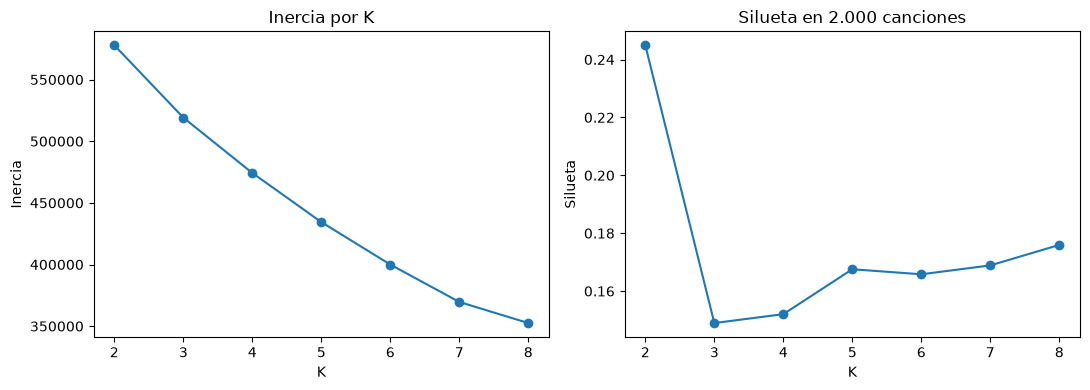

In [10]:
cluster_scaler = StandardScaler().fit(train_data[list(NUMERIC_FEATURES)])
cluster_features = cluster_scaler.transform(train_data[list(NUMERIC_FEATURES)])
sample_indices = np.random.default_rng(SEED).choice(
    len(train_data), size=min(2_000, len(train_data)), replace=False
)
cluster_rows = []
cluster_fits = {}
for k in range(2, 9):
    clustering = KMeans(n_clusters=k, random_state=SEED, n_init=10).fit(cluster_features)
    sample_labels = clustering.labels_[sample_indices]
    cluster_rows.append(
        {
            "K": k,
            "inercia": clustering.inertia_,
            "silueta_muestra": silhouette_score(cluster_features[sample_indices], sample_labels),
            "grupo_mínimo_pct": 100 * np.bincount(clustering.labels_).min() / len(train_data),
        }
    )
    cluster_fits[k] = clustering
cluster_evidence = pd.DataFrame(cluster_rows)
display(cluster_evidence.round(3))

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].plot(cluster_evidence["K"], cluster_evidence["inercia"], marker="o")
axes[0].set(title="Inercia por K", xlabel="K", ylabel="Inercia")
axes[1].plot(cluster_evidence["K"], cluster_evidence["silueta_muestra"], marker="o")
axes[1].set(title="Silueta en 2.000 canciones", xlabel="K", ylabel="Silueta")
plt.tight_layout()
plt.show()

La selección de K considera silueta, curva de inercia, tamaño mínimo e interpretabilidad del
perfil. La regla inicial toma el mayor valor de silueta entre soluciones con todos los grupos de al
menos 1% del entrenamiento; tras observar los perfiles se documenta si esa elección produce una
segmentación útil o solo separa extremos. No se usa `popularity` para cambiar K.

K elegido sin consultar popularity: 2


,canciones,duration_ms,danceability,energy,loudness,speechiness,acousticness,instrumentalness,liveness,valence,tempo,popularidad_mediana,popularidad_media
cluster,,,,,,,,,,,,,
0,54011,217053.0,0.607,0.762,-6.140,0.055,0.078,0.000,0.145,0.527,125.000,34.0,33.919
1,17781,198560.0,0.468,0.295,-13.033,0.039,0.828,0.004,0.116,0.265,107.736,29.0,30.794


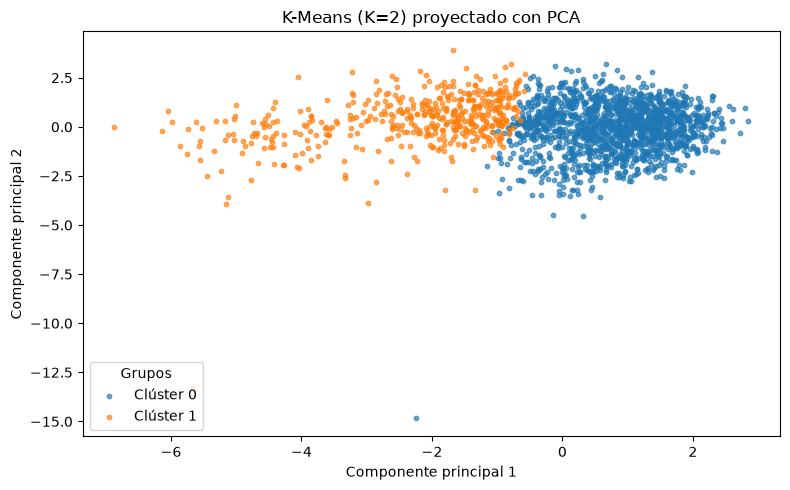

Varianza explicada por PCA: [0.289 0.152] ; suma: 0.441
Figura guardada en: reports\figures\ea2\04c_cesar_clusters_pca.png


In [11]:
eligible = cluster_evidence.loc[cluster_evidence["grupo_mínimo_pct"].ge(1)]
if eligible.empty:
    eligible = cluster_evidence
chosen_k = int(eligible.sort_values(["silueta_muestra", "K"], ascending=[False, True]).iloc[0]["K"])
chosen_clustering = cluster_fits[chosen_k]
cluster_profile = train_data[list(NUMERIC_FEATURES) + ["popularity"]].copy()
cluster_profile["cluster"] = chosen_clustering.labels_
sizes = cluster_profile.groupby("cluster").size().rename("canciones")
medians = cluster_profile.groupby("cluster")[list(NUMERIC_FEATURES)].median()
posthoc = cluster_profile.groupby("cluster")["popularity"].agg(
    popularidad_mediana="median", popularidad_media="mean"
)
profile = pd.concat([sizes, medians, posthoc], axis=1)
print(f"K elegido sin consultar popularity: {chosen_k}")
display(profile.round(3))

pca = PCA(n_components=2, random_state=SEED).fit(cluster_features)
sample_projection = pca.transform(cluster_features[sample_indices])
fig, ax = plt.subplots(figsize=(8, 5))
for cluster_id in range(chosen_k):
    mask = chosen_clustering.labels_[sample_indices] == cluster_id
    ax.scatter(
        sample_projection[mask, 0],
        sample_projection[mask, 1],
        color=plt.get_cmap("tab10")(cluster_id),
        s=10,
        alpha=0.65,
        label=f"Clúster {cluster_id}",
    )
ax.set(
    xlabel="Componente principal 1",
    ylabel="Componente principal 2",
    title=f"K-Means (K={chosen_k}) proyectado con PCA",
)
ax.legend(title="Grupos", loc="lower left")
plt.tight_layout()
figure_path = PROJECT_PATHS.figures / "ea2" / "04c_cesar_clusters_pca.png"
figure_path.parent.mkdir(parents=True, exist_ok=True)
fig.savefig(figure_path, dpi=150, bbox_inches="tight")
plt.show()
print(
    "Varianza explicada por PCA:",
    np.round(pca.explained_variance_ratio_, 3),
    "; suma:",
    round(pca.explained_variance_ratio_.sum(), 3),
)
print("Figura guardada en:", figure_path.relative_to(PROJECT_PATHS.root))

Las dos componentes explican el 44,1 % de la variación de los atributos musicales: la gráfica conserva parte de la información y comprime el resto. Se usa solo para visualizar los clústeres; K-Means se ajustó en el espacio completo de atributos escalados.


### Sensibilidad de K elegido a duración y `loudness`

Se conserva K elegido, la semilla y el conjunto de entrenamiento. Primero se aplica `log1p` únicamente
a `duration_ms` antes de escalar; en un experimento separado se excluye `loudness`, manteniendo
las otras nueve variables. Cada escala y K-Means se reajusta desde cero. Se comparan silueta en
los mismos 2.000 IDs, tamaños y perfiles con medianas en unidades originales. La concordancia se
resume con ARI, que no depende del número arbitrario asignado a cada clúster. Para leer los
perfiles se alinean los nombres de los dos grupos buscando la mayor coincidencia de canciones;
este alineamiento no cambia las asignaciones ni el ARI. No se usa `popularity` para elegir o
ajustar grupos.

In [12]:
baseline_labels = chosen_clustering.labels_
numeric_original = train_data[list(NUMERIC_FEATURES)]
duration_log = numeric_original.copy()
duration_log["duration_ms"] = np.log1p(duration_log["duration_ms"])
without_loudness = numeric_original.drop(columns="loudness")

stability_rows = []
profile_rows = []
for variant, values in (
    ("original", numeric_original),
    ("duración_log1p", duration_log),
    ("sin_loudness", without_loudness),
):
    if variant == "original":
        labels = baseline_labels.copy()
        scaled_values = cluster_features
    else:
        scaled_values = StandardScaler().fit_transform(values)
        labels = KMeans(n_clusters=chosen_k, random_state=SEED, n_init=10).fit_predict(
            scaled_values
        )
        if np.mean(labels == baseline_labels) < 0.5:
            labels = 1 - labels
    sizes = np.bincount(labels, minlength=chosen_k)
    stability_rows.append(
        {
            "variante": variant,
            "variables": values.shape[1],
            "silueta_muestra": silhouette_score(
                scaled_values[sample_indices], labels[sample_indices]
            ),
            "ARI_vs_original": adjusted_rand_score(baseline_labels, labels),
            "coincidencia_pct": 100 * np.mean(baseline_labels == labels),
            "grupo_0": int(sizes[0]),
            "grupo_1": int(sizes[1]),
        }
    )
    original_with_group = numeric_original.copy()
    original_with_group["grupo"] = labels
    for group_id, group in original_with_group.groupby("grupo"):
        medians = group[list(NUMERIC_FEATURES)].median()
        profile_rows.append(
            {
                "variante": variant,
                "grupo": int(group_id),
                "canciones": len(group),
                **medians.to_dict(),
            }
        )

stability = pd.DataFrame(stability_rows)
stability_profiles = pd.DataFrame(profile_rows)
display(stability.round(3))
display(stability_profiles.round(3))

,variante,variables,silueta_muestra,ARI_vs_original,coincidencia_pct,grupo_0,grupo_1
0,original,10,0.245,1.000,100.000,54011,17781
1,duración_log1p,10,0.241,0.968,99.258,53954,17838
2,sin_loudness,9,0.209,0.807,95.194,51769,20023


,variante,grupo,canciones,duration_ms,danceability,energy,loudness,speechiness,acousticness,instrumentalness,liveness,valence,tempo
0,original,0,54011,217053.0,0.607,0.762,-6.140,0.055,0.078,0.000,0.145,0.527,125.000
1,original,1,17781,198560.0,0.468,0.295,-13.033,0.039,0.828,0.004,0.116,0.265,107.736
2,duración_log1p,0,53954,217846.5,0.606,0.763,-6.137,0.054,0.077,0.000,0.144,0.525,125.000
3,duración_log1p,1,17838,196084.5,0.469,0.295,-13.014,0.040,0.829,0.004,0.116,0.268,107.598
4,sin_loudness,0,51769,217200.0,0.609,0.775,-6.089,0.056,0.067,0.000,0.147,0.532,125.024
5,sin_loudness,1,20023,200973.0,0.482,0.322,-11.858,0.039,0.804,0.001,0.116,0.287,108.184


### Hipótesis de uso para revisar el catálogo

Los perfiles pueden servir como **estratos de auditoría** del ranking retrospectivo. En una
revisión manual se tomaría una muestra del perfil energético/sonoro y otra del perfil
acústico/tranquilo, y se contaría en cada una cuántas canciones con popularidad ≥ 70 quedaron
fuera del 10% mejor puntuado. Si un perfil concentra omisiones, el equipo podría investigar
variables ausentes —por ejemplo, fecha y exposición— y comprobar la misma pregunta con datos más
representativos antes de cambiar una regla de selección. Esta es una **hipótesis por evaluar**:
el notebook no ha medido aún la cobertura del ranking por clúster. La silueta modesta y los cambios
al quitar `loudness` impiden tratar los grupos como categorías fijas para asignar promoción.

## 9. Resultados, conclusiones y límites

**Comparación supervisada.** En la partición aleatoria compartida, Ridge con todas las variables fue elegido en validación y obtuvo MAE **11,915**, RMSE **16,643** y R² **0,348** en prueba. La referencia mediana tuvo MAE **17,250**; Ridge redujo el MAE en **5,335 puntos (30,9%)**. El árbol completo alcanzó MAE **14,508**. Al retirar solo los géneros, Ridge subió a **16,671** y el árbol a **15,693**. En esta muestra los géneros aportan señal predictiva, pero el origen fue muestreado con 1.000 filas por género: esta ganancia puede depender del diseño y no demuestra un efecto causal ni garantiza generalización a otra distribución.

**Errores y KPI.** El candidato fijado por validación es mucho menos preciso en los extremos: MAE **24,448** para las **1.863** canciones con popularidad 0 y **36,759** para las **653** con popularidad ≥ 70; sus MAE son 8,040 en `(0,35)` (n=7.361) y 10,546 en `[35,70)` (n=8.071). En el desglose explícito, el MAE fue **11,704** en 16.431 canciones no explícitas y **14,198** en 1.517 explícitas; son diferencias descriptivas, no efectos de `explicit`. El análisis por género muestra soporte, MAE, RMSE y recuperación para cada grupo con al menos 100 canciones únicas; las etiquetas múltiples hacen que los grupos no sean sumables.

En la lista retrospectiva del 10% (1.795 canciones), Ridge completo recuperó **159 de 653** canciones ≥ 70: precisión **8,9%**, recall **24,3%** y *lift* **2,435** frente a una prevalencia de **3,6%** en esta prueba. Sin géneros recuperó 136 (*lift* 2,082); el árbol completo recuperó 119. El ranking supera una selección aleatoria de igual tamaño en esta muestra, pero la popularidad real ya está en los datos: el KPI no prueba utilidad comercial ni éxito futuro.

**Artistas principales no vistos.** La prueba agrupada contiene **18.193 canciones** de **3.528 artistas principales**, sin artistas principales compartidos con entrenamiento; entrenamiento tiene **14.111 artistas principales**. La selección se repitió en validación agrupada independiente. Ridge completo obtuvo MAE **12,102**, RMSE **16,740** y R² **0,302**, frente a MAE **16,707** de la referencia agrupada. Aunque el resultado es cercano al de la prueba aleatoria, son canciones distintas; no atribuyas la diferencia solo a excluir artistas. Además, **2.633 canciones** de la prueba agrupada tienen un artista secundario presente en entrenamiento (en cualquier rol), de modo que el diagnóstico no representa artistas totalmente aislados.

**Clústeres.** La regla basada en silueta, tamaño mínimo e interpretabilidad eligió K=**2** (silueta **0,245**): 54.011 canciones forman un perfil más energético/sonoro y 17.781 uno más acústico/tranquilo. Sus medianas de popularidad son 34 y 29, consultadas después de ajustar los grupos. Las dos componentes PCA explican **44,1%** de la variación y se usan solo para visualizar; K-Means se ajusta en los atributos escalados originales. Con `log1p(duration_ms)`, ARI fue **0,968** y la silueta 0,241; al retirar `loudness`, ARI bajó a **0,807** y la silueta a 0,209. Los perfiles dependen de variables y escala, así que son estratos exploratorios, no categorías objetivas ni causas de popularidad.

**Conclusión y uso responsable.** Ridge con géneros es el mejor candidato de esta comparación, pero los errores altos en populares muestran que la predicción numérica comprime los extremos. El ranking del 10% recupera más canciones populares que una selección aleatoria dentro de esta muestra, mientras que el experimento por artistas principales mantiene una mejora sobre su referencia con colaboradores secundarios compartidos. Estos resultados permiten formular preguntas para una revisión humana del catálogo; no justifican promociones automáticas. La fuente es histórica, está artificialmente balanceada por género y carece de fechas y exposición, por lo que no acredita desempeño sobre el catálogo natural ni anticipa lanzamientos futuros. El notebook 05 deberá reproducir las cifras del equipo y servir como fuente de las conclusiones finales.
